In [1]:
import os
import sys

sys.path.append(os.path.abspath(os.path.join("..")))

import operator
from typing import Annotated, TypedDict, cast

import arxiv
from IPython.display import Image, display
from langchain_core.messages import (
    AIMessage,
    HumanMessage,
    SystemMessage,
    get_buffer_string,
)
from langchain_core.runnables import RunnableConfig
from langgraph.checkpoint.memory import MemorySaver
from langgraph.graph import END, START, MessagesState, StateGraph
from pydantic import BaseModel, Field

from utils.utils import Models, TavilyClient, TinyFish, Trace, get_invoke_options

os.environ["LANGGRAPH_ALLOWED_MSGPACK_MODULES"] = "__main__"


In [2]:
models = Models()
nvidia_model = models.create_nvidia_model()
trace = Trace()
invoke_options = get_invoke_options()
tiny_fish = TinyFish()
tavily_client = TavilyClient()


d:\Bluebird\Code 1\Langchain-Foundation\.venv\Lib\site-packages\langchain_nvidia_ai_endpoints\_common.py:269: UserWarning: Found nvidia/nemotron-3.5-bolt-e4b in available_models, but type is unknown and inference may fail.
  warnings.warn(


In [11]:
results = tavily_client.search("peptide use in women over 40")

In [ ]:
results["results"]

In [16]:
acceptable_results = [
    result for result in results["results"] if len(result["content"]) > 800
]

In [17]:
acceptable_results

[{'url': 'https://drbnaples.com/top-benefits-of-peptides-for-women',
  'title': 'What Are the Top Benefits of Peptides for Women?',
  'content': 'To learn more about the numerous health-promoting benefits offered to aging women in Naples by peptide therapy, schedule your appointment at Dr. B’s by calling (239) 261-9990.\n\n## FAQ: Peptide Therapy for Women\n\nWhat are the best peptides for women over 40?\n\nSermorelin for fat loss and energy, and BPC-157 for healing and reducing inflammation, are commonly used by women over 40 who want to age well and feel more balanced.\n\nCan peptides help with menopause symptoms? [...] Other peptides are also effective at helping balance hormonal levels in aging women, making peptide therapy an ideal treatment for perimenopausal and postmenopausal women seeking ways to tame the aging process. In addition to balancing hormone levels, these peptides support thyroid function and insulin sensitivity, and help manage estrogen and testosterone imbalances.

In [18]:
for result in acceptable_results:
    print(result["url"])
    print(result["content"])
    print("-" * 50)

https://drbnaples.com/top-benefits-of-peptides-for-women
To learn more about the numerous health-promoting benefits offered to aging women in Naples by peptide therapy, schedule your appointment at Dr. B’s by calling (239) 261-9990.

## FAQ: Peptide Therapy for Women

What are the best peptides for women over 40?

Sermorelin for fat loss and energy, and BPC-157 for healing and reducing inflammation, are commonly used by women over 40 who want to age well and feel more balanced.

Can peptides help with menopause symptoms? [...] Other peptides are also effective at helping balance hormonal levels in aging women, making peptide therapy an ideal treatment for perimenopausal and postmenopausal women seeking ways to tame the aging process. In addition to balancing hormone levels, these peptides support thyroid function and insulin sensitivity, and help manage estrogen and testosterone imbalances. Dr. B’s Naples practice determines which peptides will work best at restoring hormonal balance b

In [4]:
client = arxiv.Client()
search = arxiv.Search(query="langchain and AI", max_results=2)
# print(type(search))
results = list(client.results(search))
for r in results:
    print(r.entry_id)
    print(r.summary)
    print(r.title)
    print("-" * 50)

http://arxiv.org/abs/2603.28944v2
Artificial intelligence (AI) predictions are increasingly used to inform human decisions. Here, using a behavioral implementation of the classic Newcomb's paradox in 1,305 participants, we show that AI predictions can also shape the reasoning people use to make a decision. In this paradigm, perceived predictive authority can alter how people reason about their future actions, leading them to forgo a guaranteed reward. Over 40% of participants treated AI as such a predictive authority about their own behavior, significantly increasing the odds of forgoing the guaranteed reward by a factor of 3.39 (95% CI: 2.45-4.70) and reducing earnings by 10.7-42.9%. The effect appeared across AI presentations and decision contexts and remained detectable even when predictions repeatedly failed. When people perceive AI as capable of predicting their personal behavior, the mere presence of AI predictions may shape their decision-making, narrowing the futures they consi

### **_Create Analysts_**

In [17]:
class Analyst(BaseModel):
    name: str = Field(description="A realistic human name of the Analyst")
    role: str = Field(description="Primary Role of the Analyst in context of the topic")
    affiliation: str = Field(description="Primary affiliation of the Analyst")
    description: str = Field(
        description="Details and description about the analyst focus,motives and concerns "
    )

    @property
    def persona(self) -> str:
        return f"Name:{self.name} \nRole:{self.role} \nAffiliation:{self.affiliation}\n Description:{self.description}"


class Perspectives(BaseModel):
    analysts: list[Analyst] = Field(
        description="Comprehensive list of analysts with their names,roles,affiliation and description "
    )


class GeneralAnalystState(TypedDict):
    topic: str
    max_analysts: int
    human_analyst_feedback: str
    analysts: list[Analyst]

In [ ]:
analyst_instructions = """You are tasked with create a set of AI personas and give each analyst a human name.Follow the instructions carefully
1. First review the research topic:{topic}
2. Examine the editorial feedback optionally provided to guide you to create the analysts:{human_analyst_feedback}
3.Determine the most interesting themes based on the documents and/or feedback above 
4. Pict the top {max_analysts} themes.
5. Assign one theme to each analyst
"""


def create_analysts(state: GeneralAnalystState):
    """Create Analysts"""
    topic = state["topic"]
    max_analysts = state["max_analysts"]
    human_analyst_feedback = state.get("human_analyst_feedback", "")

    sys_msg = analyst_instructions.format(
        topic=topic,
        max_analysts=max_analysts,
        human_analyst_feedback=human_analyst_feedback,
    )
    llm_structured = nvidia_model.with_structured_output(Perspectives)
    response = llm_structured.invoke(
        [SystemMessage(content=sys_msg)]
        + [HumanMessage(content="Generate the set of analysts")],
        **invoke_options,
    )

    return {"analysts": response.analysts}  # pyright:ignore[reportAttributeAccessIssue]


def human_feedback(state: GeneralAnalystState):
    """Dummy node"""
    pass


def should_continue(state: GeneralAnalystState):
    human_analyst_feedback = state.get("human_analyst_feedback", "")
    if human_analyst_feedback:
        return "create_analysts"
    return END


In [5]:
thread: RunnableConfig = {"configurable": {"thread_id": "1"}}

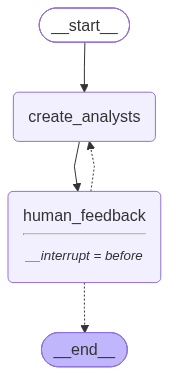

In [6]:
builder = StateGraph(GeneralAnalystState)
builder.add_node("create_analysts", create_analysts)
builder.add_node("human_feedback", human_feedback)
builder.add_edge(START, "create_analysts")
builder.add_conditional_edges(
    "human_feedback", should_continue, ["create_analysts", END]
)
builder.add_edge("create_analysts", "human_feedback")
graph = builder.compile(checkpointer=MemorySaver(), interrupt_before=["human_feedback"])
display(Image(graph.get_graph().draw_mermaid_png()))

In [7]:
topic = "The benefits of adopting LangGraph as an agent framework"
max_analysts = 3


In [ ]:
for event in graph.stream(
    {"topic": topic, "max_analysts": max_analysts},  # pyright:ignore[reportArgumentType]
    config=thread,
    stream_mode="values",
):
    analysts = event.get("analysts", "")
    if analysts:
        for analyst in analysts:
            print(f"Name:{analyst.name}")
            print(f"Role:{analyst.role}")
            print(f"Affiliation:{analyst.affiliation}")
            print(f"Description:{analyst.description}")
            print("-" * 50)

d:\Bluebird\Code 1\Langchain-Foundation\.venv\Lib\site-packages\langchain_nvidia_ai_endpoints\chat_models.py:1397: UserWarning: Model 'nvidia/nemotron-3.5-bolt-e4b' is not known to support structured output. Your output may fail at inference time.
  warnings.warn(


Name:Elias Vance
Role:LangGraph Architecture & Design Focus (How it works, state management)
Affiliation:Core Framework Expert
Description:Deep dive into LangGraph's graph structures, state handling, and modularity. Focus: Technical implementation benefits.
--------------------------------------------------
Name:Seraphina Chen
Role:Agent Complexity and Workflow Automation Focus (Handling multi-step reasoning, loops)
Affiliation:AI Workflow Strategist
Description:Examines how LangGraph simplifies complex, multi-step agentic workflows, enabling reliable loops and state persistence. Focus: Operational robustness.
--------------------------------------------------
Name:Marcus Holloway
Role:Adoption & Practical Use Case Focus (Comparison to alternatives, speed to value)
Affiliation:Industry Adoption Consultant
Description:Compares LangGraph against traditional chains/frameworks (e.g., basic LangChain) regarding development speed, debugging ease, and real-world business value. Focus: ROI and

In [9]:
# LANGGRAPH_STRICT_MSGPACK = False
graph.update_state(
    thread,
    {
        "human_analyst_feedback": "Add an additional analyst who is an Entrepreneur from a startup and assign a lead role to one of the analysts",
        "max_analysts": 4,
    },
    as_node="human_feedback",
)

Deserializing unregistered type __main__.Analyst from checkpoint. This will be blocked in a future version. Set LANGGRAPH_STRICT_MSGPACK=true to block now, or add to allowed_msgpack_modules to allow explicitly: [('__main__', 'Analyst')]


{'configurable': {'thread_id': '1',
  'checkpoint_ns': '',
  'checkpoint_id': '1f1d485b-00dc-64dd-8002-af4706769a35'}}

In [10]:
state = graph.get_state(thread)
state.next

('create_analysts',)

In [11]:
for event in graph.stream(None, thread, stream_mode="values"):
    analysts = event.get("analysts", "")
    if analysts:
        for analyst in analysts:
            print(f"Name:{analyst.name}")
            print(f"Role:{analyst.role}")
            print(f"Affiliation:{analyst.affiliation}")
            print(f"Description:{analyst.description}")
            print("-" * 50)

Name:Elias Vance
Role:LangGraph Architecture & Design Focus (How it works, state management)
Affiliation:Core Framework Expert
Description:Deep dive into LangGraph's graph structures, state handling, and modularity. Focus: Technical implementation benefits.
--------------------------------------------------
Name:Seraphina Chen
Role:Agent Complexity and Workflow Automation Focus (Handling multi-step reasoning, loops)
Affiliation:AI Workflow Strategist
Description:Examines how LangGraph simplifies complex, multi-step agentic workflows, enabling reliable loops and state persistence. Focus: Operational robustness.
--------------------------------------------------
Name:Marcus Holloway
Role:Adoption & Practical Use Case Focus (Comparison to alternatives, speed to value)
Affiliation:Industry Adoption Consultant
Description:Compares LangGraph against traditional chains/frameworks (e.g., basic LangChain) regarding development speed, debugging ease, and real-world business value. Focus: ROI and

d:\Bluebird\Code 1\Langchain-Foundation\.venv\Lib\site-packages\langchain_nvidia_ai_endpoints\chat_models.py:1397: UserWarning: Model 'nvidia/nemotron-3.5-bolt-e4b' is not known to support structured output. Your output may fail at inference time.
  warnings.warn(


Name:Dr. Evelyn Reed
Role:Lead Research Scientist
Affiliation:Academic AI Lab
Description:Expert in complex multi-agent system design and theoretical performance of graph-based workflows.
--------------------------------------------------
Name:Marcus Chen
Role:AI Solution Architect
Affiliation:Enterprise Tech Consulting
Description:Focuses on practical implementation, integration challenges, and scaling LangGraph in production environments.
--------------------------------------------------
Name:Sofia Ramirez
Role:Product Manager
Affiliation:Mid-sized SaaS Company
Description:Examines user experience, feature roadmap impact, and how LangGraph improves end-user agent reliability.
--------------------------------------------------
Name:Liam O'Connell
Role:Startup Entrepreneur
Affiliation:Early-stage AI Startup
Description:Focuses on speed-to-market, cost-efficiency, and how LangGraph provides a competitive advantage in lean development.
--------------------------------------------------


In [12]:
state = graph.get_state(thread)
state.next

('human_feedback',)

In [13]:
for event in graph.stream(None, thread, stream_mode="updates"):
    print("---Node---")
    node_name = next(iter(event.keys()))
    print(node_name)

---Node---
human_feedback


d:\Bluebird\Code 1\Langchain-Foundation\.venv\Lib\site-packages\langchain_nvidia_ai_endpoints\chat_models.py:1397: UserWarning: Model 'nvidia/nemotron-3.5-bolt-e4b' is not known to support structured output. Your output may fail at inference time.
  warnings.warn(


---Node---
create_analysts
---Node---
__interrupt__


In [14]:
graph.update_state(thread, {"human_analyst_feedback": None}, as_node="human_feedback")

{'configurable': {'thread_id': '1',
  'checkpoint_ns': '',
  'checkpoint_id': '1f1d485b-6042-61eb-8006-48d8c65009b2'}}

In [15]:
for event in graph.stream(None, thread, stream_mode="updates"):
    print("---Node---")
    node_name = next(iter(event.keys()))
    print(node_name)


In [17]:
final_state = graph.get_state(thread)
analysts = final_state.values.get("analysts")
if analysts:
    for analyst in analysts:
        print(f"Name:{analyst.name}")
        print(f"Role:{analyst.role}")
        print(f"Affiliation:{analyst.affiliation}")
        print(f"Description:{analyst.description}")
        print("-" * 50)

Name:Dr. Evelyn Reed
Role:Lead AI Architect
Affiliation:Research Institute
Description:Focuses on the technical merits and graph implementation of LangGraph.
--------------------------------------------------
Name:Marcus Chen
Role:Software Engineer
Affiliation:Tech Consultancy
Description:Examines LangGraph's practical use in building complex, stateful agents.
--------------------------------------------------
Name:Sofia Ramirez
Role:Product Manager
Affiliation:SaaS Company
Description:Analyzes how adopting LangGraph impacts product development lifecycle and user experience.
--------------------------------------------------
Name:Ben Carter
Role:Startup Entrepreneur
Affiliation:Early-Stage Startup
Description:Evaluates the ROI, speed-to-market, and scalability benefits for new ventures.
--------------------------------------------------


### **_Interview_**

In [5]:
class InterviewState(MessagesState):
    max_num_turns: int
    context: Annotated[list, operator.add]
    analyst: Analyst
    interview: str
    sections: list


class SearchQuery(BaseModel):
    search_query: str = Field(description="Search query for retrieval")

In [6]:
question_instructions = """You are tasked with interviewing an expert to learn about a specific topic,
Your goal is boil down to interesting and specific insights related to your topic. 
1.Interesting:Insights that people find surprising and non obvious. 
2.Specific: Insights that would avoid generalities and include specific examples from the expert.
Here is your topic of focus and set of gaols:{goals}
Begin by introducing yourself with your name that fits in your persona and then ask your questions 
Continue to ask questions to drill down and refine your understanding of the topic. 
When you are satisfied with the understanding and the answers,complete the interview with:"Thank you so much for your help!" 
Remember to stay in your character throughout your response,reflecting your persona and goals provided to you
"""

In [7]:
def generate_questions(state: InterviewState):
    """Node to generate questions"""
    analyst = state["analyst"]
    messages = state["messages"]

    sys_msg = question_instructions.format(goals=analyst.persona)
    question = nvidia_model.invoke(
        [SystemMessage(content=sys_msg)] + messages, **invoke_options
    )
    return {"messages": [question]}

In [8]:
search_instructions = """ 
You will be give a conversation between an analyst and an expert.
your goal is to generate a well-structured query for use in retrieval and /or web-search related to the conversation.
First,analyze the full conversation.
pay attention to the final question posed by the analyst and based on the final question create a well structured search query
"""

In [9]:
def web_search(state: InterviewState):
    structured_llm = nvidia_model.with_structured_output(SearchQuery)
    search_query = structured_llm.invoke([search_instructions] + state["messages"])
    data = tiny_fish.search.query(search_query.search_query)  # pyright:ignore[reportAttributeAccessIssue]
    formatted_docs = "\n\n".join(
        [f'<Document href="{doc.url}">{doc.snippet}</Document>' for doc in data.results]
    )
    return {"context": [formatted_docs]}

In [10]:
def arxiv_search(state: InterviewState):
    """search arxiv"""
    client = arxiv.Client()
    structured_llm = nvidia_model.with_structured_output(SearchQuery)
    search_query = structured_llm.invoke([search_instructions] + state["messages"])
    results = client.results(arxiv.Search(search_query.search_query, max_results=5))

    formatted_docs = "\n\n---\n\n".join(
        [f'<Document href="{doc.entry_id}">{doc.summary}</Document>' for doc in results]
    )

    return {"context": [formatted_docs]}

In [ ]:
answer_instructions = """You are an expert being interviewed by an analyst
Here is the analyst area of focus:{goals}
Tp answer question,use this context:
{context}
When answering questions,follow these guidelines:
1.Use only the information provided in the context.
2.Do no introduce external information or make assumptions beyond what is explicitly stated in the context.
3.The context contain sources at the top of each individual document.
4. Include these sources with your answers whenever it is relevant. For example, for source #1 use [1].
5.List your sources in order at the bottom of your answer.
6. If the source is: <Document source="assistant/docs/llama3_1.pdf" page="7"/>' then just list: 
[1] assistant/docs/llama3_1.pdf, page 7 
        
And skip the addition of the brackets as well as the Document source preamble in your citation.

"""

In [12]:
def generate_answer(state: InterviewState):
    """Noe to answer a question"""
    analyst = state["analyst"]
    messages = state["messages"]
    context = state["context"]

    system_message = answer_instructions.format(goals=analyst.persona, context=context)
    answer = nvidia_model.invoke([SystemMessage(system_message)] + messages)
    answer.name = "expert"
    return {"messages": [answer]}


def save_interview(state: InterviewState):
    """Save Interview"""
    messages = state["messages"]
    interview = get_buffer_string(messages)
    return {"interview": interview}


def route_messages(state: InterviewState, name: str = "expert"):
    """Route between question and answer"""

    messages = state["messages"]
    max_num_turns = state.get("max_num_turns", 2)

    num_response = len(
        [m for m in messages if isinstance(m, AIMessage) and m.name == name]
    )

    if num_response > max_analysts:
        return "save_interview"
    last_question = cast(str, messages[-2])
    if "Thank you so much for your help!" in last_question:
        return "save_interview"
    return "ask_question"


In [13]:
section_writer_instructions = """You are an expert technical writer. 
            
Your task is to create a short, easily digestible section of a report based on a set of source documents.

1. Analyze the content of the source documents: 
- The name of each source document is at the start of the document, with the <Document tag.
        
2. Create a report structure using markdown formatting:
- Use ## for the section title
- Use ### for sub-section headers
        
3. Write the report following this structure:
a. Title (## header)
b. Summary (### header)
c. Sources (### header)

4. Make your title engaging based upon the focus area of the analyst: 
{focus}

5. For the summary section:
- Set up summary with general background / context related to the focus area of the analyst
- Emphasize what is novel, interesting, or surprising about insights gathered from the interview
- Create a numbered list of source documents, as you use them
- Do not mention the names of interviewers or experts
- Aim for approximately 400 words maximum
- Use numbered sources in your report (e.g., [1], [2]) based on information from source documents
        
6. In the Sources section:
- Include all sources used in your report
- Provide full links to relevant websites or specific document paths
- Separate each source by a newline. Use two spaces at the end of each line to create a newline in Markdown.
- It will look like:

### Sources
[1] Link or Document name
[2] Link or Document name

7. Be sure to combine sources. For example this is not correct:

[3] https://ai.meta.com/blog/meta-llama-3-1/
[4] https://ai.meta.com/blog/meta-llama-3-1/

There should be no redundant sources. It should simply be:

[3] https://ai.meta.com/blog/meta-llama-3-1/
        
8. Final review:
- Ensure the report follows the required structure
- Include no preamble before the title of the report
- Check that all guidelines have been followed"""


In [14]:
def write_section(state: InterviewState):
    interview = state["interview"]
    context = state["context"]
    analyst = state["analyst"]

    system_message = section_writer_instructions.format(focus=analyst.description)
    section = nvidia_model.invoke(
        [SystemMessage(content=system_message)]
        + [HumanMessage(content=f"use this sources to write your section {context}")]
    )

    return {"sections": [section.content]}

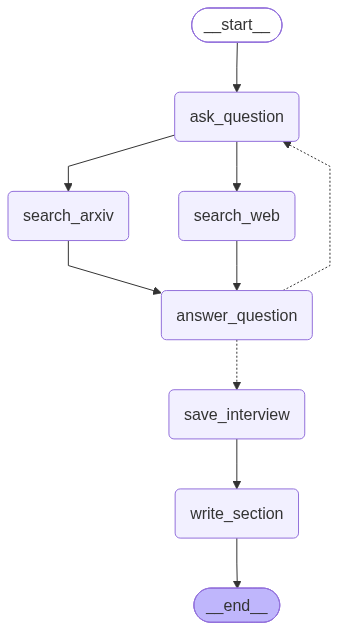

In [19]:
interview_builder = StateGraph(InterviewState)
interview_builder.add_node("ask_question", generate_questions)
interview_builder.add_node("search_web", web_search)
interview_builder.add_node("search_arxiv", arxiv_search)
interview_builder.add_node("answer_question", generate_answer)
interview_builder.add_node("save_interview", save_interview)
interview_builder.add_node("write_section", write_section)

interview_builder.add_edge(START, "ask_question")
interview_builder.add_edge("ask_question", "search_web")
interview_builder.add_edge("ask_question", "search_arxiv")
interview_builder.add_edge("search_web", "answer_question")
interview_builder.add_edge("search_arxiv", "answer_question")
interview_builder.add_conditional_edges(
    "answer_question", route_messages, ["ask_question", "save_interview"]
)
interview_builder.add_edge("save_interview", "write_section")
interview_builder.add_edge("write_section", END)
interview_graph = interview_builder.compile(checkpointer=MemorySaver()).with_config(
    run_name="Conduct_interviews"
)
display(Image(interview_graph.get_graph(xray=True).draw_mermaid_png()))
